In [1]:
from IPython.display import HTML, display

# Печатные стили: шесть страниц; проверочные выводы остаются в ноутбуке.
display(HTML(r'''<style>
@page { size: A4; margin: 12mm 13mm; }
@media print {
  html, body { background: white !important; color: #243746 !important; }
  body, .jp-RenderedHTMLCommon { font-family: "DejaVu Sans", sans-serif !important; font-size: 10pt !important; line-height: 1.28 !important; }
  body { padding: 0 !important; margin: 0 !important; }
  main, #notebook, .jp-Notebook { padding: 0 !important; margin: 0 !important; }
  .jp-Cell { padding: 0 !important; margin: 0 0 2mm !important; break-inside: avoid; }
  .jp-Cell-inputWrapper, .jp-Cell-outputWrapper, .jp-OutputArea, .jp-OutputArea-child { padding: 0 !important; margin: 0 !important; }
  .jp-InputPrompt, .jp-OutputPrompt, .jp-Cell-inputCollapser, .jp-Cell-outputCollapser { display: none !important; }
  .jp-RenderedHTMLCommon { padding: 0 !important; }
  h1 { font-size: 19pt !important; line-height: 1.15 !important; margin: 0 0 4mm !important; }
  h2 { font-size: 14pt !important; margin: 3mm 0 2mm !important; color: #226887 !important; }
  h3 { font-size: 11pt !important; margin: 2.5mm 0 1.5mm !important; }
  p { margin: 0 0 2mm !important; }
  ul, ol { margin: 0 0 2mm !important; padding-left: 5mm !important; }
  li { margin-bottom: 1mm !important; }
  table { font-size: 8.8pt !important; line-height: 1.2 !important; width: 100% !important; border-collapse: collapse !important; margin: 1mm 0 2mm !important; table-layout: fixed; }
  th, td { text-align: left !important; padding: 1.3mm 1.6mm !important; vertical-align: top !important; white-space: normal !important; overflow-wrap: anywhere; border-bottom: .2mm solid #d4dee3 !important; }
  thead th { background: #e8f0f4 !important; color: #243746 !important; }
  tbody tr:nth-child(even) { background: #f7f9fa !important; }
  code { font-size: 8.2pt !important; background: transparent !important; }
  .jp-OutputArea-output { overflow: visible !important; }
  .jp-RenderedImage { text-align: center; }
  .jp-RenderedImage img { max-width: 100% !important; width: auto !important; height: auto !important; object-fit: contain; }
  [id="cell-id=f535cdbc"] { break-before: page !important; }
  [id="cell-id=06aec0b4"] { break-before: page !important; }
  [id="cell-id=286ea911"] { break-before: page !important; }
  [id="cell-id=92971cf7"] { break-before: page !important; }
  [id="cell-id=0ffb65f3"] { break-before: page !important; }
  [id="cell-id=3793b859"] { display: none !important; }
  [id="cell-id=ade6b738"] { display: none !important; }
  [id="cell-id=d1912c8e"] img { max-height: 65mm !important; }
  [id="cell-id=b539d96c"] img { max-height: 78mm !important; }
  [id="cell-id=871d1e2c"] img { max-height: 78mm !important; }
  [id="cell-id=364fed41"] img { max-height: 75mm !important; }
  [id="cell-id=3c4ef5fd"] img { max-height: 76mm !important; }
  [id="cell-id=3407d178"] th:first-child, [id="cell-id=3407d178"] td:first-child { width: 30%; }
  [id="cell-id=5ca9e5c1"] th:first-child, [id="cell-id=5ca9e5c1"] td:first-child { width: 80%; }
  [id="cell-id=f9039156"] th:first-child, [id="cell-id=f9039156"] td:first-child { width: 40%; }
  [id="cell-id=183f03de"] table { font-size: 8.2pt !important; }
  [id="cell-id=183f03de"] th:first-child, [id="cell-id=183f03de"] td:first-child { width: 14%; }
  [id="cell-id=97441f89"], [id="cell-id=e3058487"] { font-size: 9pt !important; line-height: 1.2 !important; }
}
</style>'''))


# Кто снизил активность и кому предложить кампанию

**Олихвер Виталий Николаевич** · Банк «Меридиан» · Лабораторная работа 1  
**Период:** 01.01.2024 - 30.06.2025. Данные синтетические.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.titlelocation': 'left',
                     'axes.titlesize': 12, 'axes.titleweight': 'bold'})
pd.set_option('display.max_colwidth', None)
BLUE, GREEN, GRAY, ORANGE = '#226887', '#29846c', '#9daab3', '#bd7136'

def show_table(table, digits=2):
    display(HTML(table.to_html(index=False, border=0, float_format=lambda value: f'{value:.{digits}f}')))

def ru(value, digits=2):
    return f'{value:.{digits}f}'.replace('.', ',')

def add_source(fig, period, n, note=''):
    fig.text(0.01, -0.02,
             f'Источник: синтетические данные банка «Меридиан», clean_data и client_metrics.\n'
             f'{period}; n = {n} клиентов; успешные положительные операции. {note}',
             ha='left', va='top', fontsize=8, color='#536773')

clean = pd.read_csv('clean_data.csv.gz',
    usecols=['client_id', 'month', 'amount', 'status', 'channel', 'category', 'mcc_code'],
    dtype={'client_id': 'string', 'mcc_code': 'string'}, keep_default_na=False, na_values=[''])
clients = pd.read_csv('client_metrics.csv', dtype={'client_id': 'string', 'branch_code': 'string'},
                      keep_default_na=False, na_values=[''])
campaign = pd.read_csv('campaign_list.csv', dtype='string')
cleaning_log = pd.read_csv('cleaning_log.csv', keep_default_na=False, na_values=[''])

cohort = clients.loc[clients['full_history']].set_index('client_id')
success = clean.loc[(clean['status'] == 'успешно') & (clean['amount'] > 0)]
full_success = success.loc[success['client_id'].isin(cohort.index)]
months = pd.period_range('2024-01', '2025-06', freq='M').astype(str)
monthly = pd.crosstab(full_success['client_id'], full_success['month']).reindex(
    index=cohort.index, columns=months, fill_value=0)
base = monthly.iloc[:, :12].sum(axis=1) / 12
recent = monthly.iloc[:, 12:].sum(axis=1) / 6
season_base = monthly.iloc[:, :6].sum(axis=1) / 6
mean_loss = (base - recent).mean()
season_loss = (season_base - recent).mean()
group_order = ['Одежда и обувь', 'Массовый без приложения', 'Карта']
assert np.allclose(base, cohort['base'])
assert np.allclose(recent, cohort['recent'])
assert campaign['client_id'].is_unique
assert campaign['client_id'].isin(clients.loc[clients['marketing_opt_in'] == 'Да', 'client_id']).all()


In [3]:
# Показатели, таблицы и заголовки графиков пересчитываются при выполнении.
# Числа в Markdown-ячейках статические: после обновления данных их сверяем отдельно.
monthly_mean = monthly.mean()
channel_monthly = pd.crosstab(full_success['month'], full_success['channel']).reindex(months, fill_value=0)
channel_change = pd.DataFrame({
    'base': channel_monthly.iloc[:12].sum() / 12 / len(cohort),
    'recent': channel_monthly.iloc[12:].sum() / 6 / len(cohort),
})
channel_change['loss'] = channel_change['base'] - channel_change['recent']
channel_loss = (channel_monthly.iloc[:6].reset_index(drop=True)
                - channel_monthly.iloc[12:].reset_index(drop=True)) / len(cohort)
channel_loss.index = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн']
online_marapr = channel_loss.loc[['Мар', 'Апр'], 'Онлайн-банк'].mean()
online_mayjun = channel_loss.loc[['Май', 'Июн'], 'Онлайн-банк'].mean()
category_monthly = pd.crosstab(full_success['month'], full_success['category']).reindex(months, fill_value=0)
category_change = pd.DataFrame({
    'base': category_monthly.iloc[:12].sum() / 12 / len(cohort),
    'recent': category_monthly.iloc[12:].sum() / 6 / len(cohort),
})
category_change['loss'] = category_change['base'] - category_change['recent']
segment_app_loss = cohort.pivot_table(index='segment', columns='has_mobile_app',
                                     values='activity_loss', aggfunc='median')
segment_app_n = pd.crosstab(cohort['segment'], cohort['has_mobile_app'])
group_data = campaign.merge(clients, on='client_id', how='left',
                            suffixes=('', '_saved'), validate='one_to_one')
group_stats = group_data.groupby('group').agg(
    n=('client_id', 'size'), base=('base', 'mean'), recent=('recent', 'mean'),
    mean_loss=('activity_loss', 'mean'), median_loss=('activity_loss', 'median'),
).reindex(group_order)
assert 3 <= len(group_stats) <= 5
assert group_stats['n'].ge(150).all() and len(campaign) <= 2000
group_series = monthly.loc[campaign['client_id'], '2025-01':'2025-06'].copy()
group_series['group'] = campaign.set_index('client_id')['group']
group_series = group_series.groupby('group').mean().reindex(group_order)
campaign_success = full_success.merge(campaign, on='client_id', how='inner', validate='many_to_one')
group_category_loss = (campaign_success.loc[campaign_success['month'] < '2025-01']
    .groupby(['group', 'category']).size().unstack(fill_value=0) / 12
    - campaign_success.loc[campaign_success['month'] >= '2025-01']
    .groupby(['group', 'category']).size().unstack(fill_value=0) / 6).div(group_stats['n'], axis=0)
group_channel_loss = (campaign_success.loc[campaign_success['month'] < '2025-01']
    .groupby(['group', 'channel']).size().unstack(fill_value=0) / 12
    - campaign_success.loc[campaign_success['month'] >= '2025-01']
    .groupby(['group', 'channel']).size().unstack(fill_value=0) / 6).div(group_stats['n'], axis=0)
clothes_share = 100 * group_category_loss.loc['Одежда и обувь', 'Одежда и обувь'] / group_stats.loc['Одежда и обувь', 'mean_loss']
card_share = 100 * group_channel_loss.loc['Карта', 'Карта'] / group_stats.loc['Карта', 'mean_loss']
mass_loss = segment_app_loss.loc['Массовый']
mass_n = segment_app_n.loc['Массовый']

# Выводы остаются обычным Markdown; эта таблица показывает источники их чисел.
report_numbers = pd.DataFrame([
    ['Очищенных операций всех статусов', len(clean)],
    ['Клиентов справочника', len(clients)],
    ['Успешных положительных операций', len(success)],
    ['Полное базовое окно: клиентов', len(cohort)],
    ['Поздняя регистрация', pd.to_datetime(clients['registration_date']).gt('2024-01-01').sum()],
    ['Ранняя регистрация, поздняя текущая карта', (pd.to_datetime(clients['registration_date']).le('2024-01-01') & ~clients['full_history']).sum()],
    ['Клиентов вне справочника', int(cleaning_log.loc[cleaning_log['field'].eq('client_id'), 'scope'].iloc[0].split('ID вне справочника: ')[1].split(';')[0])],
    ['Средняя частота 2024', base.mean()], ['Средняя частота 2025', recent.mean()],
    ['Потеря к году', mean_loss], ['Потеря к тем же месяцам', season_loss],
    ['Рост Токена', -channel_change.loc['Токен', 'loss']],
    ['Потеря Карты', channel_change.loc['Карта', 'loss']],
    ['Массовый без приложения: медиана', mass_loss['Нет']],
    ['Массовый с приложением: медиана', mass_loss['Да']],
    ['Доля потери одежды в группе, %', clothes_share],
    ['Доля потери Карты в группе, %', card_share],
    ['Вне кампании в справочнике', len(clients) - len(campaign)],
    ['Решений в журнале', len(cleaning_log)],
], columns=['Показатель', 'Значение'])
show_table(report_numbers.round(3), digits=3)
display(channel_change.round(3))
display(category_change.round(3))
display(group_stats.round(3))
display(group_channel_loss.round(3))
display(group_category_loss.round(3))
display(group_series.round(3))


Показатель,Значение
Очищенных операций всех статусов,596775.000
Клиентов справочника,5659.000
Успешных положительных операций,577837.000
Полное базовое окно: клиентов,4874.000
Поздняя регистрация,112.000
"Ранняя регистрация, поздняя текущая карта",673.000
Клиентов вне справочника,341.000
Средняя частота 2024,6.927
Средняя частота 2025,5.524
Потеря к году,1.403


,base,recent,loss
channel,,,
Карта,3.652,2.552,1.100
Онлайн-банк,1.019,0.680,0.339
СБП,1.240,1.021,0.219
Токен,1.016,1.272,-0.256


,base,recent,loss
category,,,
АЗС,0.634,0.531,0.102
Аптеки,0.499,0.396,0.103
Кафе и рестораны,0.891,0.741,0.150
Одежда и обувь,0.813,0.538,0.276
Онлайн-сервисы,0.483,0.395,0.089
Продукты,1.816,1.462,0.354
Развлечения и досуг,0.520,0.441,0.079
Связь и интернет,0.538,0.434,0.104
Транспорт,0.732,0.587,0.145


,n,base,recent,mean_loss,median_loss
group,,,,,
Одежда и обувь,242,8.412,5.107,3.304,2.917
Массовый без приложения,513,6.016,2.120,3.897,3.250
Карта,504,7.220,3.299,3.922,3.250


channel,Карта,Онлайн-банк,СБП,Токен
group,,,,
Карта,2.958,0.611,0.488,-0.136
Массовый без приложения,2.198,0.676,0.614,0.409
Одежда и обувь,1.705,0.636,0.573,0.390


category,АЗС,Аптеки,Кафе и рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и интернет,Транспорт
group,,,,,,,,,
Карта,0.369,0.299,0.484,0.370,0.275,1.092,0.289,0.292,0.452
Массовый без приложения,0.304,0.356,0.401,0.342,0.259,1.185,0.228,0.365,0.456
Одежда и обувь,0.143,0.136,0.285,1.783,0.132,0.364,0.156,0.136,0.171


,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
group,,,,,,
Одежда и обувь,4.298,5.136,5.463,5.488,4.839,5.421
Массовый без приложения,2.400,2.524,2.470,2.127,1.727,1.470
Карта,3.135,3.569,3.837,3.282,2.962,3.006


## 1. Главное

1. **Частота снизилась с 6,93 до 5,52 операции на клиента в месяц.** Потеря — 1,40 к среднему месяцу 2024 и 0,92 к тем же месяцам. Календарное сравнение сохраняет спад.
2. **Рост «Токена» компенсирует часть потери «Карты»:** +0,256 против −1,100 операции на клиента в месяц.
3. **В массовом сегменте выше потеря у клиентов без приложения:** медиана 2,25 против 1,25 операции в месяц. Это связь признаков; история установки приложения неизвестна.
4. **В кампании 1259 клиентов:** одежда — 242, массовый сегмент без приложения — 513, «Карта» — 504. Каждый включён один раз и дал согласие.

## 2. Контекст

Нужны от трёх до пяти групп для возвращения частоты использования, минимум 150 клиентов в каждой, максимум 2000 всего. Предложения опираются на наблюдаемые изменения; результат кампании предстоит проверить.

## 3. Данные и ограничения

После очистки: **596775 операций всех статусов**, **5659 клиентов**; успешных положительных операций — **577837**. Сравниваются **4874 клиента** с регистрацией и открытием текущей карты не позже 01.01.2024. Исключены 112 поздних регистраций и 673 более поздние карты: история в основном начинается с текущей карты, поэтому их база неполна. В допустимом окне месяцы без операций считаются нулевыми.

**Метрика.** Активность — число уникальных успешных положительных операций за календарный месяц: 2024 год делим на 12, январь–июнь 2025 — на 6. Потеря — абсолютная разница частот всех каналов и валют. Метрика не видит уменьшения сумм при прежнем числе операций и полностью компенсированной смены канала; среднее сглаживает изменения к концу периода. Отказы и возвраты не добавляют операций; связи возврата с исходной оплатой нет.

Справочник содержит действующих клиентов на 30.06.2025. Нет операций других банков, истории предложений, откликов и контактов. Приложение известно только на дату среза; часть операций без времени, категория иногда расходится с MCC. Пересчёт доходов ×1000 и ограничение дат рождения — рабочие допущения; доход и возраст в правила кампании не входят. Внутреннюю полноту выгрузки подтвердить нельзя.


## 4. Находки

### 4.1. Снижение сохраняется при сравнении одинаковых месяцев


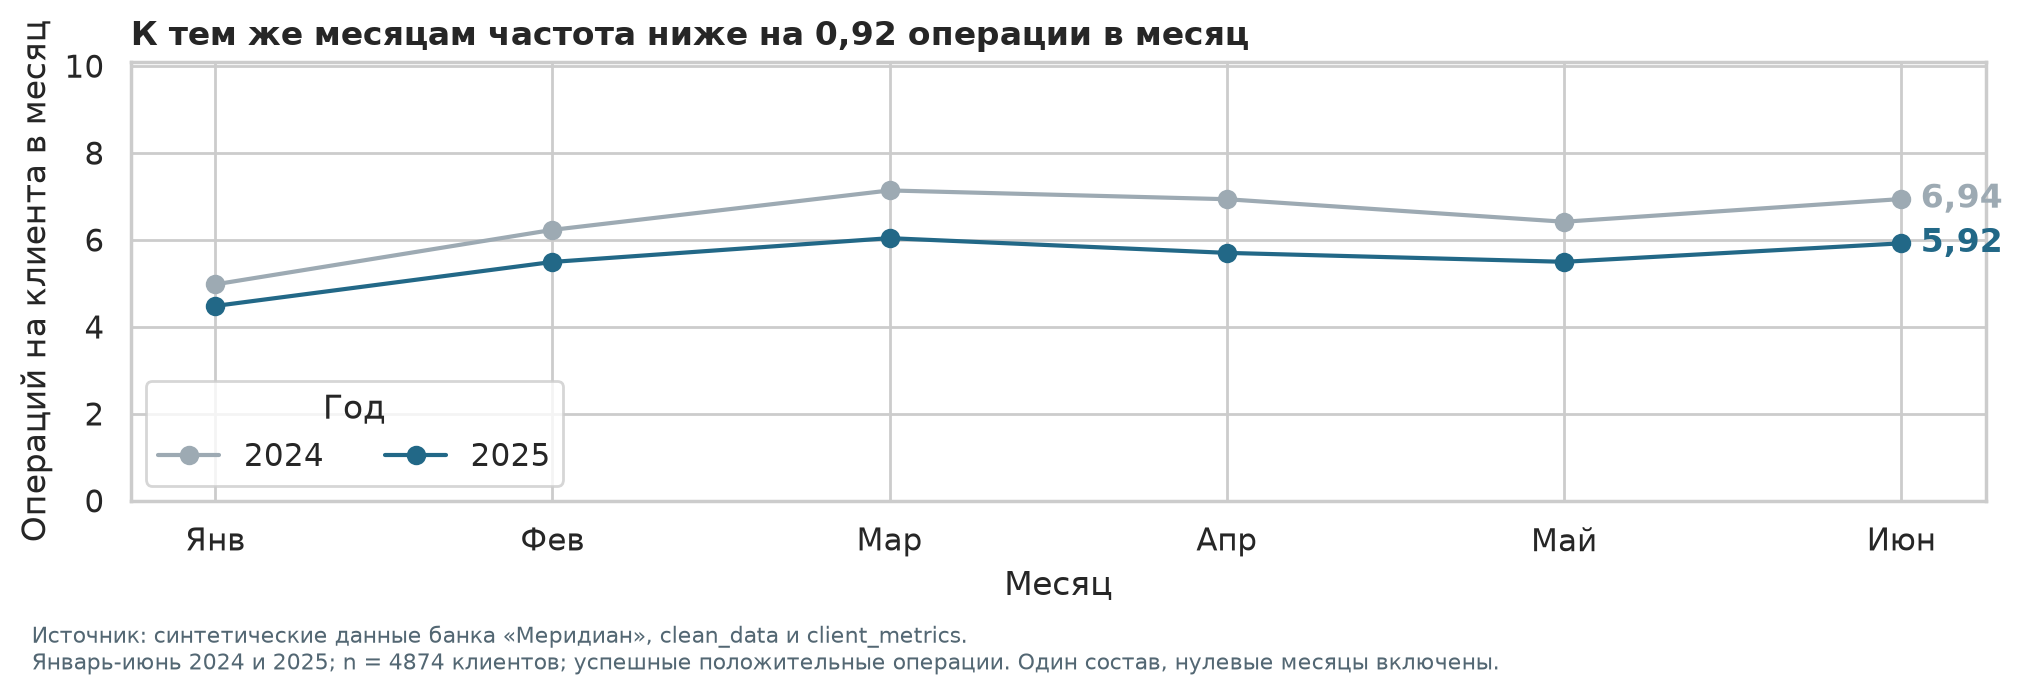

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.0), layout='constrained')
ax.plot(range(1, 7), monthly_mean.iloc[:6], marker='o', color=GRAY, label='2024')
ax.plot(range(1, 7), monthly_mean.iloc[12:], marker='o', color=BLUE, label='2025')
ax.set_xticks(range(1, 7), ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн'])
ax.set_ylim(0, monthly_mean.max() * 1.16)
ax.set_title(f'К тем же месяцам частота ниже на {ru(season_loss)} операции в месяц')
ax.set_xlabel('Месяц')
ax.set_ylabel('Операций на клиента в месяц')
ax.legend(title='Год', ncols=2, loc='lower left')
for offset, values, color in [(0, monthly_mean.iloc[:6], GRAY), (12, monthly_mean.iloc[12:], BLUE)]:
    ax.annotate(ru(values.iloc[-1]), (6, values.iloc[-1]), xytext=(7, 0),
                textcoords='offset points', va='center', color=color, fontweight='bold')
add_source(fig, 'Январь-июнь 2024 и 2025', len(cohort), 'Один состав, нулевые месяцы включены.')
plt.show()


Разница **0,92** меньше основной потери **1,40** к среднему месяцу всего 2024. Календарный состав окон влияет на размер спада. Двух полугодий недостаточно для вывода о долгосрочном тренде.

### 4.2. Оплата смартфоном растёт, провал онлайн-банка ослабевает


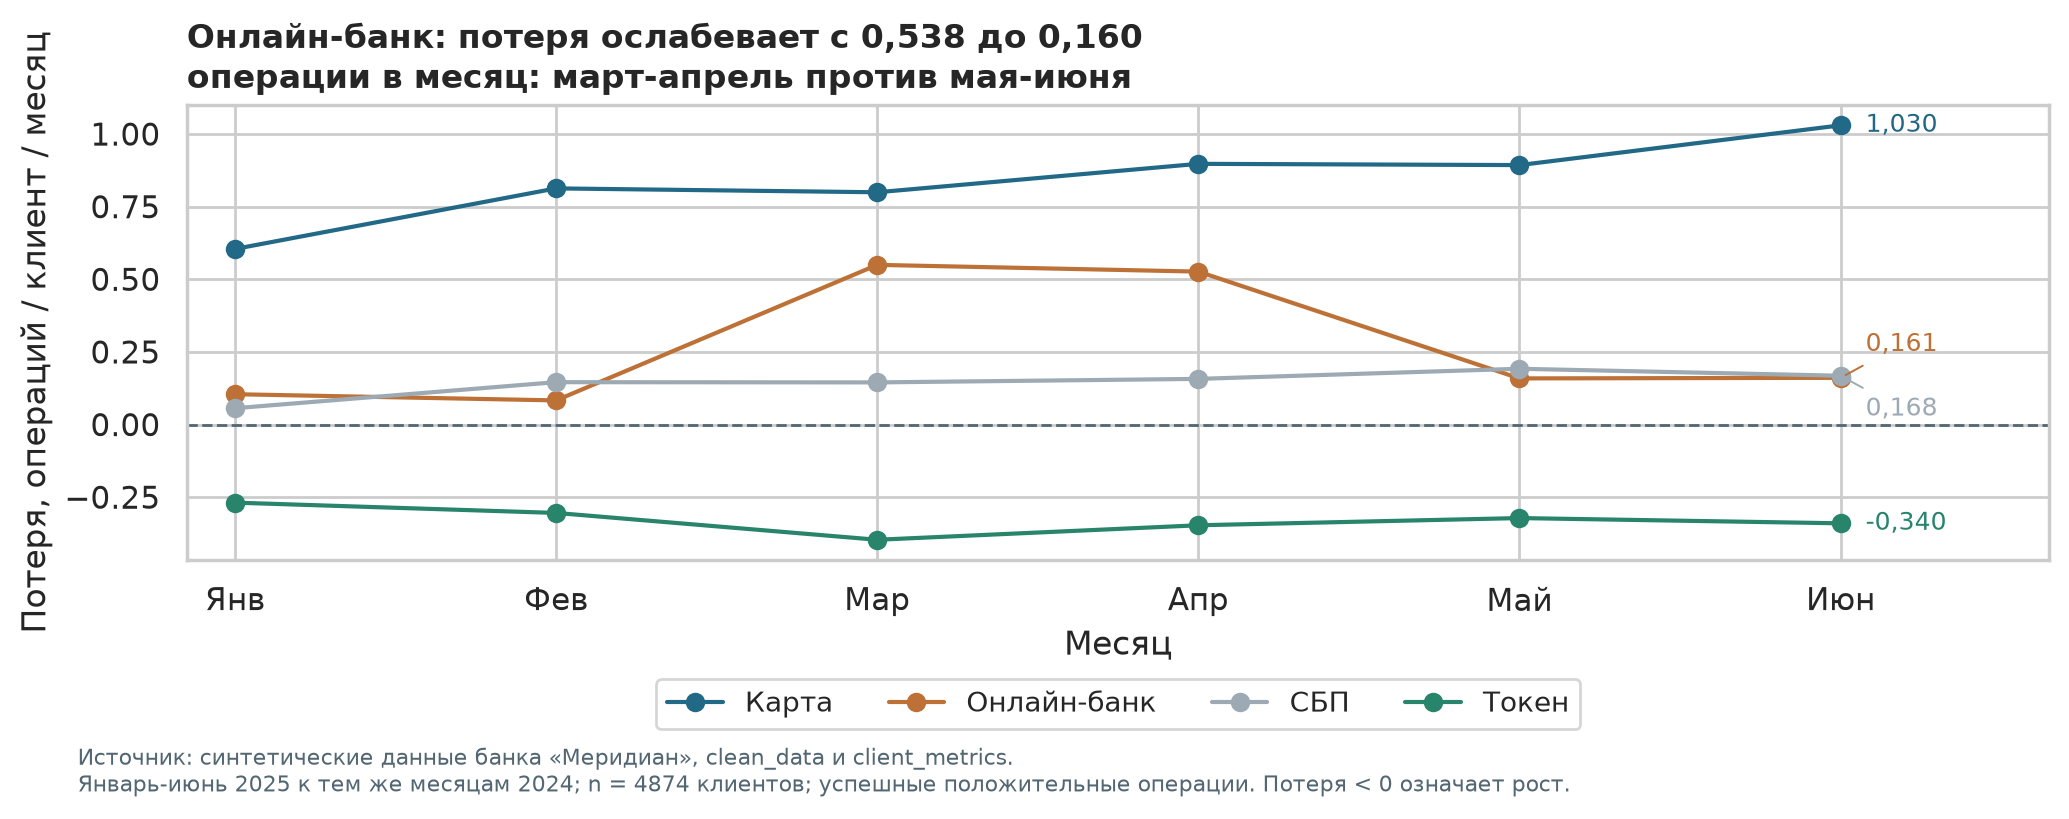

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6), layout='constrained')
channel_colors = {'Карта': BLUE, 'Токен': GREEN, 'СБП': GRAY, 'Онлайн-банк': ORANGE}
for name in channel_loss:
    values = channel_loss[name]
    ax.plot(range(6), values, marker='o', label=name, color=channel_colors[name])
    dy = {'Онлайн-банк': 12, 'СБП': -12}.get(name, 0)
    ax.annotate(ru(values.iloc[-1], 3), (5, values.iloc[-1]), xytext=(9, dy),
                textcoords='offset points', va='center', color=channel_colors[name], fontsize=9,
                arrowprops={'arrowstyle': '-', 'color': channel_colors[name], 'lw': 0.7} if dy else None)
ax.axhline(0, color='#536773', linestyle='--', linewidth=1)
ax.set_xticks(range(6), ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн'])
ax.set_xlim(-0.15, 5.65)
ax.set_title(f'Онлайн-банк: потеря ослабевает с {ru(online_marapr, 3)} до {ru(online_mayjun, 3)}\n'
             'операции в месяц: март-апрель против мая-июня')
ax.set_xlabel('Месяц')
ax.set_ylabel('Потеря, операций / клиент / месяц')
ax.legend(ncols=4, fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.23))
add_source(fig, 'Январь-июнь 2025 к тем же месяцам 2024', len(cohort), 'Потеря < 0 означает рост.')
plt.show()


Рост «Токена» сочетается с общей потерей частоты; переход именно тех же клиентов между каналами этим не доказан. Временный провал онлайн-банка нельзя автоматически считать продолжающимся отказом от канала. Его причина неизвестна.


### 4.3. Продукты и одежда дают наибольшие средние потери


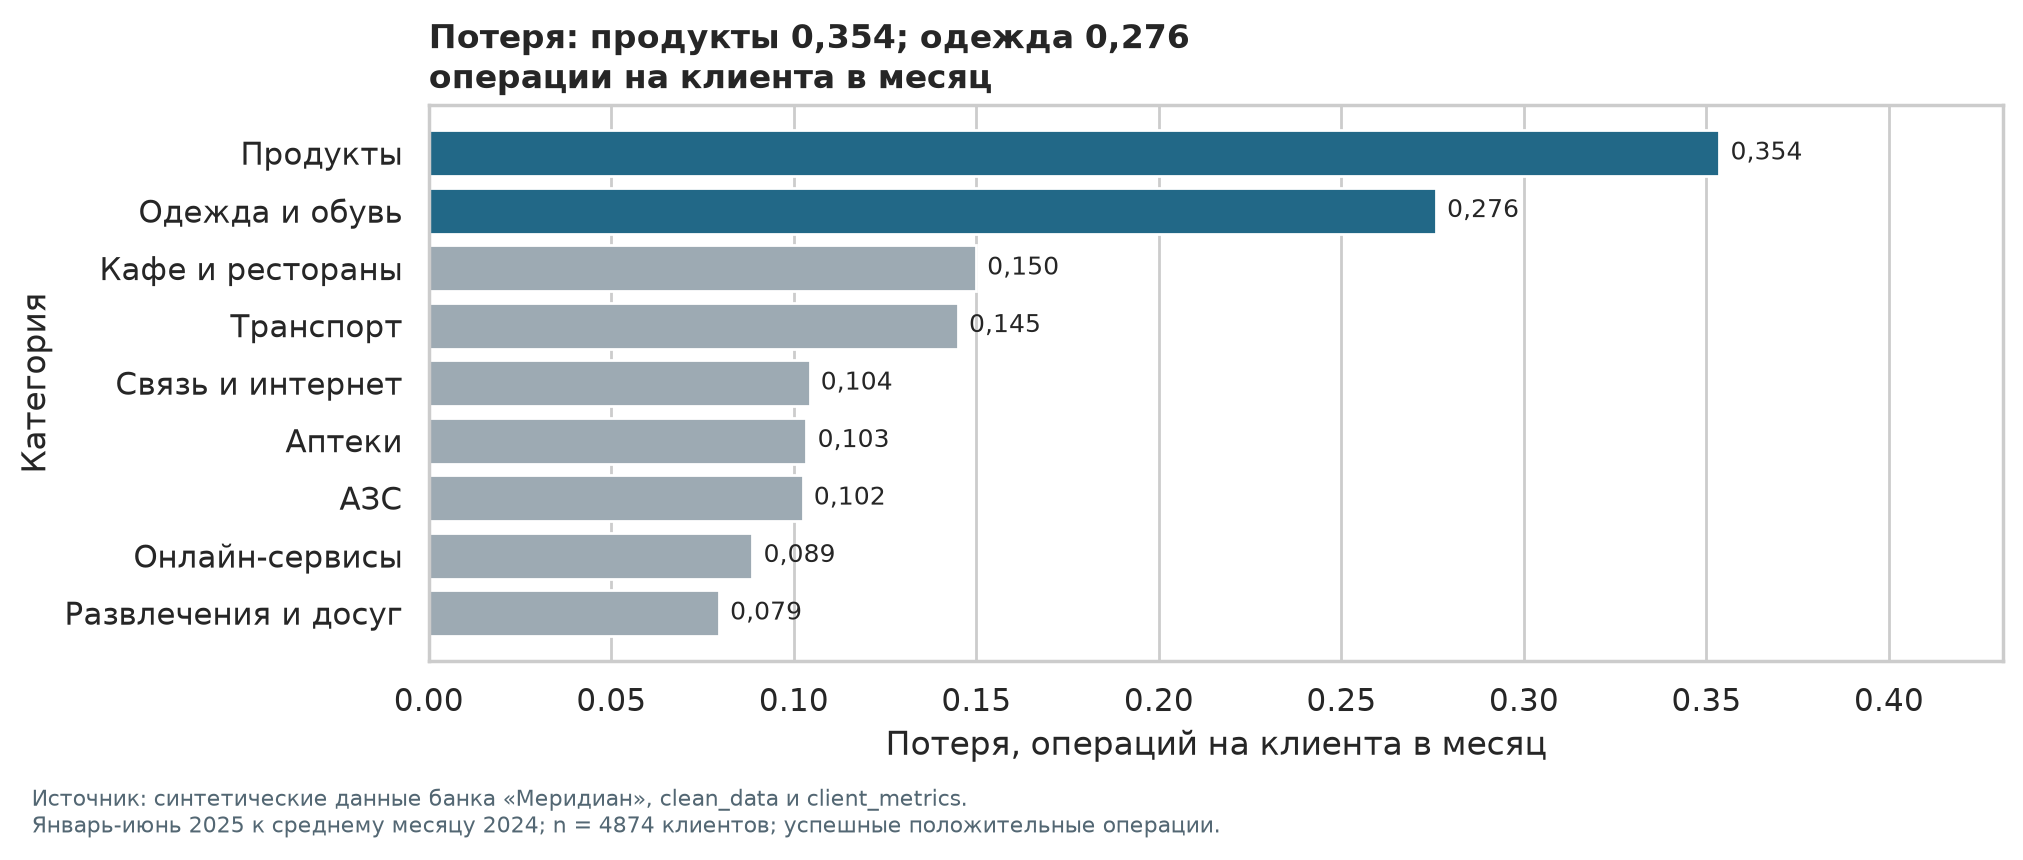

In [6]:
values = category_change['loss'].sort_values()
fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
bars = ax.barh(values.index, values.values,
    color=[BLUE if name in ['Продукты', 'Одежда и обувь'] else GRAY for name in values.index])
ax.bar_label(bars, labels=[ru(v, 3) for v in values], padding=4, fontsize=9)
ax.set_title(f'Потеря: продукты {ru(values["Продукты"], 3)}; одежда {ru(values["Одежда и обувь"], 3)}\n'
             'операции на клиента в месяц')
ax.set_xlabel('Потеря, операций на клиента в месяц')
ax.set_ylabel('Категория')
ax.set_xlim(0, values.max() * 1.22)
ax.grid(axis='y', visible=False)
add_source(fig, 'Январь-июнь 2025 к среднему месяцу 2024', len(cohort))
plt.show()


Средние потери положительны во всех **9 категориях**. Положение категории в общей базе ещё не объясняет снижение каждого клиента: сценарий одежды далее проверяется по индивидуальным вкладам. Категории и каналы описывают одни операции, их вклады между собой не складываются.

### 4.4. Различие по приложению сохраняется внутри массового сегмента


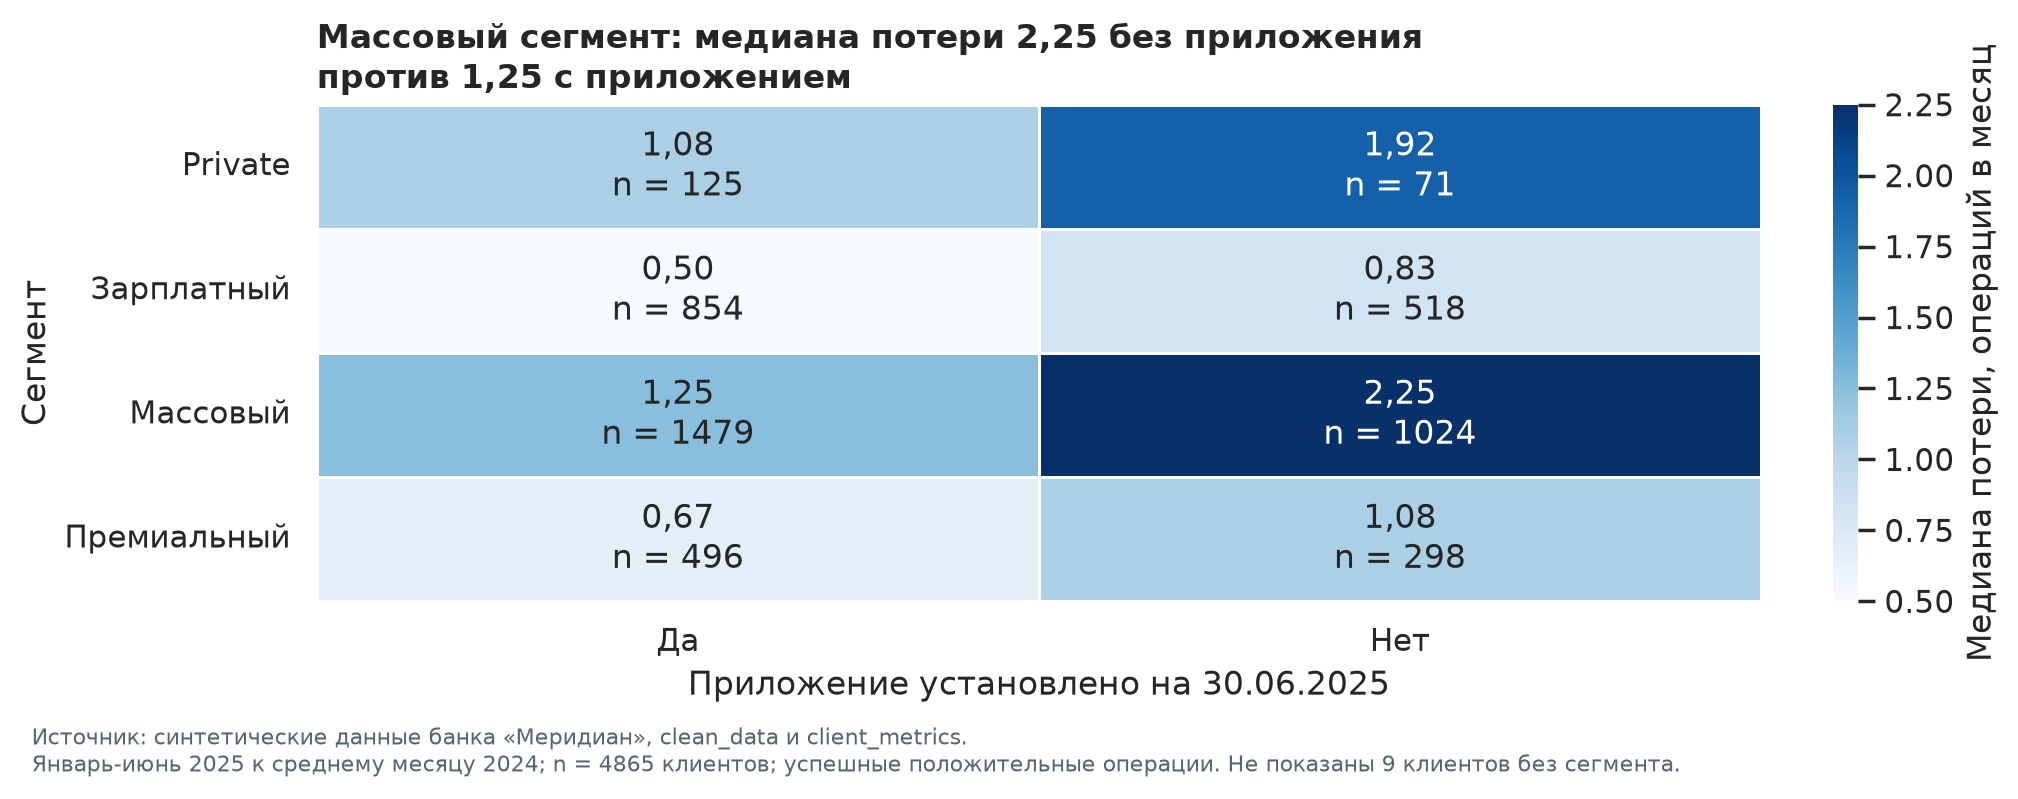

In [7]:
labels = segment_app_loss.copy().astype(object)
for segment in labels.index:
    for app in labels.columns:
        labels.loc[segment, app] = (f'{ru(segment_app_loss.loc[segment, app])}\n'
                                    f'n = {segment_app_n.loc[segment, app]}')
fig, ax = plt.subplots(figsize=(10, 3.5), layout='constrained')
sns.heatmap(segment_app_loss, annot=labels, fmt='', cmap='Blues', linewidths=1,
            cbar_kws={'label': 'Медиана потери, операций в месяц'}, ax=ax)
ax.set_title(f'Массовый сегмент: медиана потери {ru(mass_loss["Нет"])} без приложения\n'
             f'против {ru(mass_loss["Да"])} с приложением')
ax.set_xlabel('Приложение установлено на 30.06.2025')
ax.set_ylabel('Сегмент')
ax.tick_params(axis='y', rotation=0)
add_source(fig, 'Январь-июнь 2025 к среднему месяцу 2024', int(segment_app_n.to_numpy().sum()),
           f'Не показаны {cohort["segment"].isna().sum()} клиентов без сегмента.')
plt.show()


Сравнение при фиксированном сегменте сохраняет различие. Истории установки и использования приложения нет, поэтому причина снижения не установлена. Для кампании дополнительно учитывается характер изменения во времени.


## 5. Группы для кампании

У всех участников доступны полные окна и есть согласие. Потеря — не менее одной операции в месяц; оба квартала 2025 ниже тех же кварталов 2024; май–июнь ниже и тех же месяцев 2024, и среднего за год.

**Кто входит:** покупали одежду хотя бы в шести месяцах 2024; массовый сегмент без приложения; более половины операций 2024 — пластиковой картой. Для одежды и «Карты» дополнительно нужен ведущий вклад соответствующей категории или канала в потерю. **Приоритет:** одежда → массовый без приложения → «Карта».


In [8]:
show_table(group_stats[['n', 'base', 'recent', 'median_loss']].reset_index().rename(columns={
    'group': 'Группа', 'n': 'Клиентов', 'base': 'База 2024', 'recent': 'Янв-июнь 2025',
    'median_loss': 'Медиана потери',
}).round(2))


Группа,Клиентов,База 2024,Янв-июнь 2025,Медиана потери
Одежда и обувь,242,8.41,5.11,2.92
Массовый без приложения,513,6.02,2.12,3.25
Карта,504,7.22,3.30,3.25


Частоты в таблице - средние операции на клиента в месяц; медиана описывает индивидуальную потерю типичного клиента.


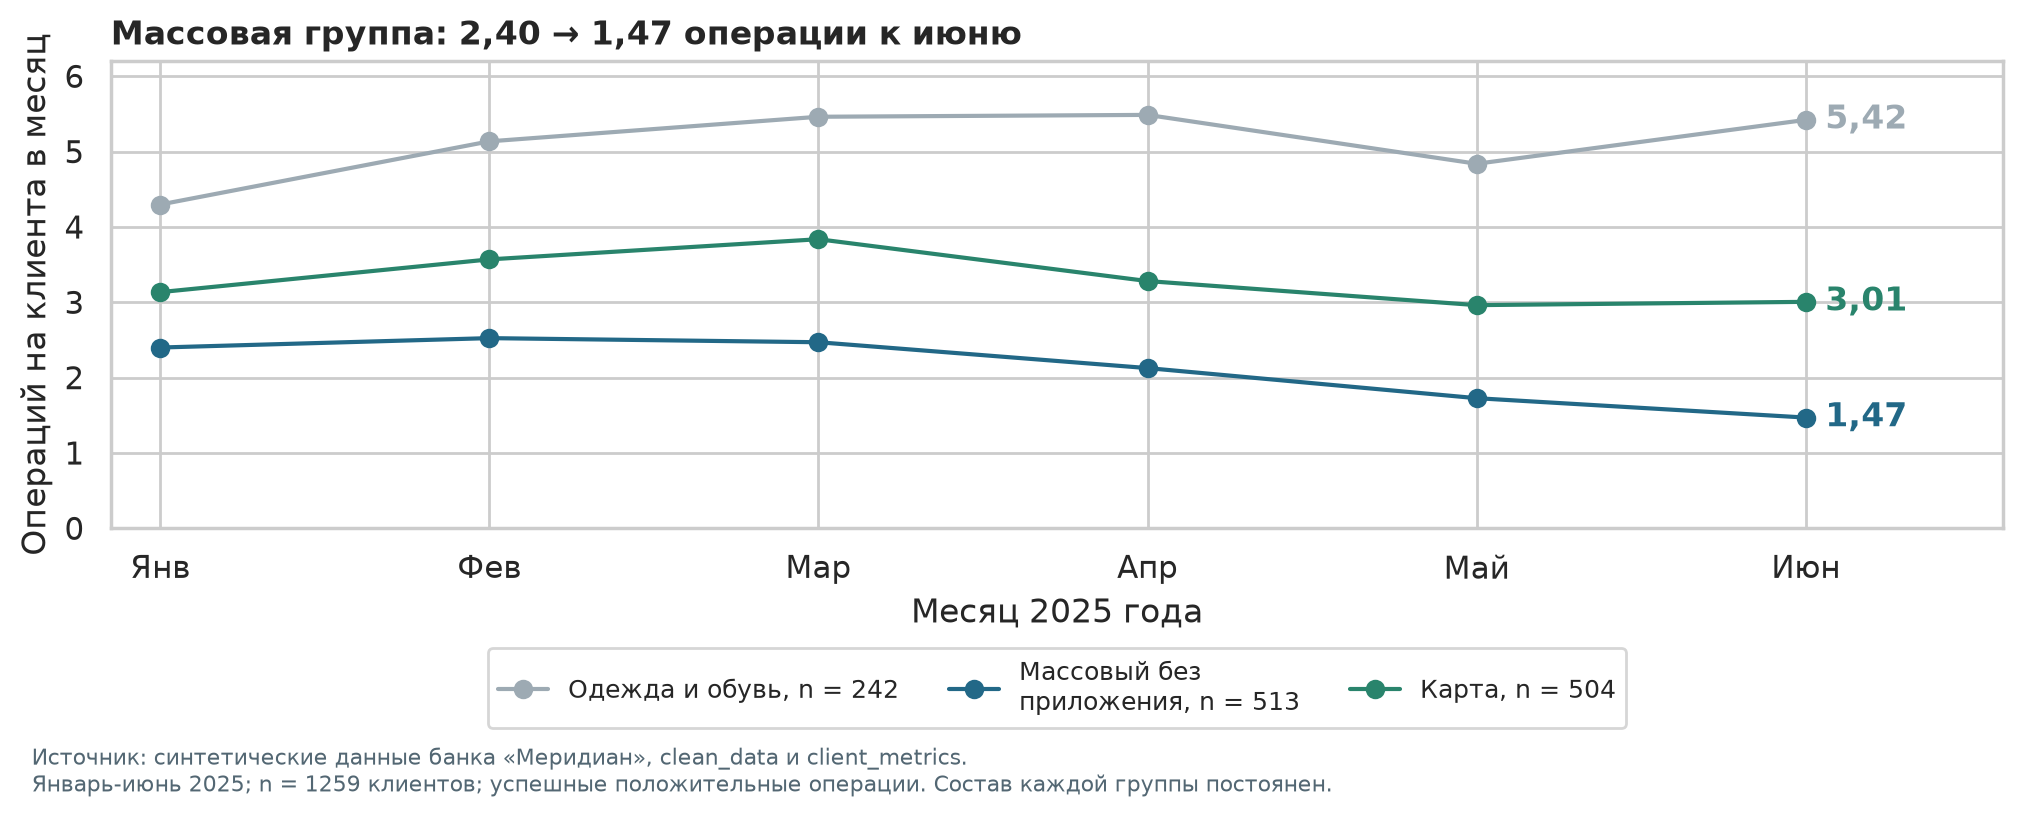

In [9]:
fig, ax = plt.subplots(figsize=(10, 3.6), layout='constrained')
for name, color in zip(group_order, [GRAY, BLUE, GREEN]):
    values = group_series.loc[name]
    label = name.replace('Массовый без приложения', 'Массовый без\nприложения')
    ax.plot(range(1, 7), values, marker='o', color=color,
            label=f'{label}, n = {group_stats.loc[name, "n"]}')
    ax.annotate(ru(values.iloc[-1]), (6, values.iloc[-1]), xytext=(7, 0),
                textcoords='offset points', va='center', color=color, fontweight='bold')
ax.set_xticks(range(1, 7), ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн'])
ax.set_xlim(0.85, 6.6)
ax.set_ylim(0, group_series.to_numpy().max() * 1.13)
ax.set_title(f'Массовая группа: {ru(group_series.loc["Массовый без приложения", "2025-01"])} → '
             f'{ru(group_series.loc["Массовый без приложения", "2025-06"])} операции к июню')
ax.set_xlabel('Месяц 2025 года')
ax.set_ylabel('Операций на клиента в месяц')
ax.legend(fontsize=9, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.23))
add_source(fig, 'Январь-июнь 2025', len(campaign), 'Состав каждой группы постоянен.')
plt.show()


**Одежда и обувь.** Категория даёт **1,78 из 3,30** потерянных операций, **54,0% совокупной потери группы**. Частота ниже базы без последовательного помесячного падения. Гипотеза — кэшбэк на одежду.

**Массовый сегмент без приложения.** **Средние потери положительны во всех каналах и категориях.** Из 3,90 потерянных операций 2,20 относятся к «Карте», 1,19 — к продуктам. Возможны предложение для повседневных покупок и помощь с удобным способом оплаты.

**Карта.** Канал даёт **2,96 из 3,92** потерянных операций, **75,4% совокупной потери группы**. Рост «Токена» на 0,14 компенсирует часть снижения. Гипотеза — бонус за возобновление оплат картой.

Доли относятся к совокупной потере группы. «Карта» была крупным каналом уже в базе: ведущий вклад задаёт тему общения, а не доказывает причину. Отклик и окупаемость предложений неизвестны.


## 6. Кого не включаем и почему

Причины применяются последовательно: клиент учтён по первой подходящей строке, количества можно складывать.


In [10]:
consent = cohort['marketing_opt_in'] == 'Да'
noticeable = cohort['activity_loss'].round(6) >= 1
quarters_lower = (cohort['q1_loss'] > 0) & (cohort['q2_loss'] > 0)
late_lower = ((cohort['late_2025'] < cohort['late_2024']) & (cohort['late_2025'] < cohort['base']))
stable_change = consent & quarters_lower & late_lower
stable = stable_change & noticeable
exclusions = pd.DataFrame({
    'Кого исключаем': [
        'Поздняя регистрация: нет полного базового окна',
        'Текущая карта открыта после начала базы при ранней регистрации',
        'Нет согласия на маркетинг среди остальных',
        'Общая частота не снизилась', 'Потеря меньше одной операции в месяц',
        'Хотя бы в одном квартале нет снижения', 'Нет снижения мая-июня хотя бы к одной базе',
        'Не подходят три содержательных правила'],
    'Клиентов': [pd.to_datetime(clients['registration_date']).gt('2024-01-01').sum(),
        (pd.to_datetime(clients['registration_date']).le('2024-01-01') & ~clients['full_history']).sum(),
        (~consent).sum(),
        (consent & (cohort['activity_loss'] <= 0)).sum(),
        (consent & (cohort['activity_loss'] > 0) & ~noticeable).sum(),
        (consent & noticeable & ~quarters_lower).sum(),
        (consent & noticeable & quarters_lower & ~late_lower).sum(), stable.sum() - len(campaign)],
})
assert exclusions['Клиентов'].sum() + len(campaign) == len(clients)
show_table(exclusions)


Кого исключаем,Клиентов
Поздняя регистрация: нет полного базового окна,112
Текущая карта открыта после начала базы при ранней регистрации,673
Нет согласия на маркетинг среди остальных,578
Общая частота не снизилась,1169
Потеря меньше одной операции в месяц,748
Хотя бы в одном квартале нет снижения,582
Нет снижения мая-июня хотя бы к одной базе,197
Не подходят три содержательных правила,341


Вне кампании **4400**, включены **1259**; вместе — весь справочник из **5659** клиентов. Отдельно исключены **341 ID вне справочника**: для них нет анкеты и согласия; в эту сумму они не входят.

Полностью компенсированная смена канала не считается общим снижением. Временного провала онлайн-банка недостаточно для контакта. Пропуски дохода, оценки и города сами по себе не исключают клиента; неизвестный сегмент мешает только массовой группе.

## 7. Что проверили и что не подтвердилось


In [11]:
login_sample = cohort.loc[(cohort['has_mobile_app'] == 'Да') & cohort['app_last_login'].notna()].copy()
login_dates = pd.to_datetime(login_sample['app_last_login'], format='ISO8601')
login_sample['months_since_login'] = (2025 - login_dates.dt.year) * 12 + 6 - login_dates.dt.month
login_corr = login_sample['months_since_login'].rank().corr(login_sample['activity_loss'].rank())
income_sample = cohort.loc[cohort['monthly_income'].notna()]
income_corr = income_sample['monthly_income'].rank().corr(income_sample['activity_loss'].rank())
income_known_segment = income_sample.loc[income_sample['segment'].notna()]
income_within = []
for name, part in income_known_segment.groupby('segment'):
    income_within.append(part['monthly_income'].rank().corr(part['activity_loss'].rank()))
city_mass = cohort.loc[cohort['segment'] == 'Массовый'].groupby('city')['activity_loss'].agg(['size', 'median'])

hypotheses = pd.DataFrame([
    ['Спад вызван только календарными различиями',
     f'Потеря {ru(mean_loss, 3)} к году и {ru(season_loss, 3)} к тем же месяцам; n = {len(cohort)}.'],
    ['Провал онлайн-банка сохраняет глубину',
     f'Потеря {ru(online_marapr, 3)} в марте-апреле и {ru(online_mayjun, 3)} в мае-июне; n = {len(cohort)}.'],
    ['Давний вход связан с большей потерей',
     f'Ранговая связь {ru(login_corr, 3)}, n = {len(login_sample)}.'],
    ['Связь дохода повторяется в сегментах',
     f'Общая {ru(income_corr, 3)} (n = {len(income_sample)}); внутри от {ru(min(income_within), 3)} до {ru(max(income_within), 3)} (n = {len(income_known_segment)}).'],
    ['У массовых клиентов Казани потеря выше Москвы',
     f'Медианы {ru(city_mass.loc["Казань", "median"])} (n = {city_mass.loc["Казань", "size"]}) и {ru(city_mass.loc["Москва", "median"])} (n = {city_mass.loc["Москва", "size"]}).'],
], columns=['Проверенное объяснение', 'Результат'])
show_table(hypotheses)


Проверенное объяснение,Результат
Спад вызван только календарными различиями,"Потеря 1,403 к году и 0,918 к тем же месяцам; n = 4874."
Провал онлайн-банка сохраняет глубину,"Потеря 0,538 в марте-апреле и 0,160 в мае-июне; n = 4874."
Давний вход связан с большей потерей,"Ранговая связь 0,006, n = 2960."
Связь дохода повторяется в сегментах,"Общая -0,100 (n = 4364); внутри от -0,023 до 0,048 (n = 4357)."
У массовых клиентов Казани потеря выше Москвы,"Медианы 1,67 (n = 739) и 1,92 (n = 606)."


Календарное сравнение сохраняет спад, провал онлайн-банка ослабевает. Общая связь дохода не повторяется внутри сегментов; городское различие также не сохраняется внутри массового сегмента.


## 8. Приложение

### 8.1. Сводка журнала изменений


In [12]:
log = cleaning_log.set_index('field')


Решений в полном журнале: **24**. Ниже - укрупнённые типы; строки разных этапов могут пересекаться и не складываются.


In [13]:
mcc_check = log.loc['category_mcc_conflict']
mcc_conflict_count = int(mcc_check['scope'].split('расхождение у ')[1].split()[0])

journal_summary = pd.DataFrame([
    ['clients; transactions', 'Полные дубли',
     f"{log.loc['clients', 'n_rows']} анкет; {log.loc['transactions', 'n_rows']} операций", 'Удалены полные копии'],
    ['client_id; txn_id', 'Противоречивые анкеты; версии операции',
     f"{log.loc['client_id, city, segment', 'n_rows']} версий анкет; {log.loc['txn_id, txn_datetime', 'n_rows']} версий операций",
     'Спорные поля в NA; версии объединены; сохранено время'],
    ['city; category', 'Разные написания',
     f"{log.loc['city', 'n_rows']} анкет; {log.loc['category', 'n_rows']} операций",
     f"{clients['city'].nunique()} городов; {clean['category'].nunique()} категорий"],
    ['category; MCC', 'Расхождения категории и кода',
     f"{mcc_conflict_count} расхождений из {mcc_check['n_rows']} проверенных операций",
     'Текст и код сохранены; добавлен флаг'],
    ['Доход; вход', 'Доход -999; вход до регистрации',
     f"{log.loc['monthly_income'].iloc[0]['n_rows']} доходов; {log.loc['app_last_login', 'n_rows']} дат", 'Заменены на NA; есть флаги'],
    ['monthly_income', 'Смешение единиц - гипотеза', f"{clients['income_scaled'].sum()} клиента",
     '×1000; исходник сохранён'],
    ['Дата; client_id', 'Вне периода; без анкеты',
     f"{log.loc['txn_datetime', 'n_rows']} и {log.loc['client_id', 'n_rows']} операций последовательно", 'Исключены из охвата'],
    ['status; amount', 'Неуспешные и возвраты', str(log.loc['status, amount', 'n_rows']) + ' операций',
     'В clean; вне частоты'],
    ['Клиентские поля', 'Пропуски дохода, оценки, входа, города, сегмента',
     str(log.loc['monthly_income, satisfaction_score, app_last_login, city, segment', 'n_rows']) + ' клиентов', 'Не заполнялись'],
], columns=['Поле', 'Что найдено', 'Сколько', 'Что сделано'])
show_table(journal_summary)


Поле,Что найдено,Сколько,Что сделано
clients; transactions,Полные дубли,40 анкет; 1283 операций,Удалены полные копии
client_id; txn_id,Противоречивые анкеты; версии операции,30 версий анкет; 217 версий операций,Спорные поля в NA; версии объединены; сохранено время
city; category,Разные написания,1629 анкет; 52234 операций,6 городов; 9 категорий
category; MCC,Расхождения категории и кода,1615 расхождений из 625997 проверенных операций,Текст и код сохранены; добавлен флаг
Доход; вход,Доход -999; вход до регистрации,50 доходов; 25 дат,Заменены на NA; есть флаги
monthly_income,Смешение единиц - гипотеза,163 клиента,×1000; исходник сохранён
Дата; client_id,Вне периода; без анкеты,82 и 29140 операций последовательно,Исключены из охвата
status; amount,Неуспешные и возвраты,18938 операций,В clean; вне частоты
Клиентские поля,"Пропуски дохода, оценки, входа, города, сегмента",4399 клиентов,Не заполнялись


### 8.2. Методика

- **Частота:** `base = N2024 / 12`, `recent = Nянв-июн2025 / 6`, `loss = base - recent`. Уникальные успешные положительные операции всех валют и каналов; нулевые месяцы включены. Регистрация и текущая карта — не позже 01.01.2024. Вклад канала/категории — та же разница, рост со знаком минус.
- **Фильтр:** согласие «Да», `round(loss, 6) >= 1`; оба квартала ниже соответствующих кварталов 2024; май–июнь ниже и мая–июня 2024, и `base`. Порог абсолютный, в операциях в месяц.
- **Правила и приоритет:** одежда в ≥6 месяцах 2024 + её максимальный вклад → массовый без приложения → доля «Карты» в 2024 >50% + её максимальный вклад. Равные максимумы допускаются. Базовые признаки описывают аудиторию, вклады — характер потери.
- **Квартили:** линейная интерполяция pandas (`interpolation='linear'`).


In [14]:
# Повторяем правила по сохранённым данным для проверки чувствительности.
client_losses = {}
for field in ['category', 'channel']:
    counts_2024 = (full_success.loc[full_success['month'] < '2025-01']
        .groupby(['client_id', field]).size().unstack(fill_value=0).reindex(cohort.index, fill_value=0) / 12)
    counts_2025 = (full_success.loc[full_success['month'] >= '2025-01']
        .groupby(['client_id', field]).size().unstack(fill_value=0).reindex(cohort.index, fill_value=0) / 6)
    client_losses[field] = (counts_2024 - counts_2025).round(6)
group_flags = pd.DataFrame(index=cohort.index)
group_flags['Одежда и обувь'] = (cohort['clothes_months_2024'].ge(6)
    & client_losses['category']['Одежда и обувь'].eq(client_losses['category'].max(axis=1)))
group_flags['Массовый без приложения'] = ((cohort['segment'] == 'Массовый') & (cohort['has_mobile_app'] == 'Нет')).fillna(False)
group_flags['Карта'] = (cohort['card_share_2024'].gt(.5)
    & client_losses['channel']['Карта'].eq(client_losses['channel'].max(axis=1)))
threshold_counts = []
for threshold in [0.5, 1, 2]:
    eligible = stable_change & (cohort['activity_loss'].round(6) >= threshold)
    assigned = pd.Series(index=cohort.index, dtype='string')
    for name in group_order:
        assigned.loc[eligible & group_flags[name] & assigned.isna()] = name
    counts = assigned.value_counts().reindex(group_order, fill_value=0)
    assert counts.ge(150).all() and counts.sum() <= 2000
    threshold_counts.append(int(counts.sum()))
    if threshold == 1:
        assigned_main = assigned.copy()
assert assigned_main.dropna().sort_index().equals(campaign.set_index('client_id')['group'].sort_index())
overlap_n = (group_flags.loc[stable].sum(axis=1) > 1).sum()
mcc_map = {'5411': 'Продукты', '5812': 'Кафе и рестораны', '5651': 'Одежда и обувь',
           '4111': 'Транспорт', '5541': 'АЗС', '7832': 'Развлечения и досуг',
           '5912': 'Аптеки', '5815': 'Онлайн-сервисы', '4814': 'Связь и интернет'}
mcc_success = full_success.assign(mcc_category=full_success['mcc_code'].map(mcc_map))
mcc_base = (mcc_success.loc[mcc_success['month'] < '2025-01']
    .groupby(['client_id', 'mcc_category']).size().unstack(fill_value=0).reindex(cohort.index, fill_value=0) / 12)
mcc_recent = (mcc_success.loc[mcc_success['month'] >= '2025-01']
    .groupby(['client_id', 'mcc_category']).size().unstack(fill_value=0).reindex(cohort.index, fill_value=0) / 6)
mcc_loss = (mcc_base - mcc_recent).round(6)
mcc_flags = group_flags.copy()
mcc_clothes_months = (mcc_success.loc[mcc_success['month'].lt('2025-01')
    & mcc_success['mcc_category'].eq('Одежда и обувь')]
    .groupby('client_id')['month'].nunique().reindex(cohort.index, fill_value=0))
mcc_flags['Одежда и обувь'] = mcc_clothes_months.ge(6) & mcc_loss['Одежда и обувь'].eq(mcc_loss.max(axis=1))
mcc_assigned = pd.Series(index=cohort.index, dtype='string')
for name in group_order:
    mcc_assigned.loc[stable & mcc_flags[name] & mcc_assigned.isna()] = name
mcc_changed = (assigned_main.fillna('Вне кампании') != mcc_assigned.fillna('Вне кампании')).sum()
age_flag_n = group_data['age_upper_flag'].sum()

sensitivity = pd.DataFrame({'Порог потери': [0.5, 1, 2], 'Клиентов': threshold_counts})
show_table(sensitivity)
sensitivity_checks = pd.DataFrame({
    'Показатель': ['Назначение изменилось по MCC', 'Кампания по MCC', 'С возрастной отметкой',
                  'Без возрастной отметки', 'Несколько правил до приоритета'],
    'Значение': [int(mcc_changed), int(mcc_assigned.notna().sum()), int(age_flag_n),
                 len(campaign) - int(age_flag_n), int(overlap_n)],
})
show_table(sensitivity_checks)


Порог потери,Клиентов
0.50,1306
1.00,1259
2.00,1024


Показатель,Значение
Назначение изменилось по MCC,3
Кампания по MCC,1258
С возрастной отметкой,37
Без возрастной отметки,1222
Несколько правил до приоритета,592


**Чувствительность.** Пороги 0,5 / 1 / 2 дают 1306 / 1259 / 1024 участников: везде три группы минимум по 150. По MCC меняют назначение 3 клиента; список — 1258. Без 37 записей с отметкой возраста остаются 1222. До приоритета 592 клиента подходят нескольким правилам. Доход и возраст в отбор не входят.

### 8.3. Использование ИИ

ИИ помог доработать код, проверить расчёты, написать текст и оформить отчёт.  
Проверены состав выборки, согласия и ограничения кампании.  
Предложения для клиентов оставлены гипотезами.
